# Unemployment in India: Exploratory Analysis

This report studies regional and monthly unemployment patterns in India and measures how the labour market changed around the COVID-19 period. The data file is the public Kaggle dataset **Unemployment in India**. The notebook text and analysis are independently written for this project.

## Load the dataset and libraries

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (11, 6)
file_path = Path.cwd() / 'Unemployment in India.csv'
if not file_path.exists():
    raise FileNotFoundError(f'Place the Kaggle CSV here: {file_path}')
raw = pd.read_csv(file_path)
print(f'Loaded {file_path.name}: {raw.shape[0]:,} rows and {raw.shape[1]} columns')
display(raw.head())

Loaded Unemployment in India.csv: 768 rows and 7 columns


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## Data quality and type preparation

The original headers contain extra spaces, and the date and measurement fields arrive as text. The following cell makes those fields ready for analysis and reports missing values before and after cleaning.

In [ ]:
print('Original data types:')
display(raw.dtypes.to_frame('dtype'))
print('Missing values before cleaning:')
display(raw.isna().sum().to_frame('missing'))

data = raw.copy()
data.columns = data.columns.str.strip()
data = data.rename(columns={
    'Date':'date', 'Region':'region', 'Area':'area',
    'Estimated Unemployment Rate (%)':'unemployment_rate',
    'Estimated Employed':'employed',
    'Estimated Labour Participation Rate (%)':'labour_participation_rate'
})
data['date'] = pd.to_datetime(data['date'], dayfirst=True, errors='coerce')
measure_columns = ['unemployment_rate', 'employed', 'labour_participation_rate']
for column in measure_columns:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data = data.dropna(subset=['date', 'region'] + measure_columns).copy()
data['month'] = data['date'].dt.to_period('M').dt.to_timestamp()
print(f'Rows remaining after cleaning: {len(data):,}')
display(data.dtypes.to_frame('dtype'))
display(data.isna().sum().to_frame('missing_after_cleaning'))

Original data types:


,dtype
Region,str
Date,str
Frequency,str
Estimated Unemployment Rate (%),float64
Estimated Employed,float64
Estimated Labour Participation Rate (%),float64
Area,str


Missing values before cleaning:


,missing
Region,28
Date,28
Frequency,28
Estimated Unemployment Rate (%),28
Estimated Employed,28
Estimated Labour Participation Rate (%),28
Area,28


Rows remaining after cleaning: 740


,dtype
region,str
date,datetime64[us]
Frequency,str
unemployment_rate,float64
employed,float64
labour_participation_rate,float64
area,str
month,datetime64[us]


,missing_after_cleaning
region,0
date,0
Frequency,0
unemployment_rate,0
employed,0
labour_participation_rate,0
area,0
month,0


## Average unemployment by region

,region,unemployment_rate
24,Tripura,28.35
8,Haryana,26.28
11,Jharkhand,20.58
2,Bihar,18.92
9,Himachal Pradesh,18.54
5,Delhi,16.50
10,Jammu & Kashmir,16.19
3,Chandigarh,15.99
20,Rajasthan,14.06
25,Uttar Pradesh,12.55


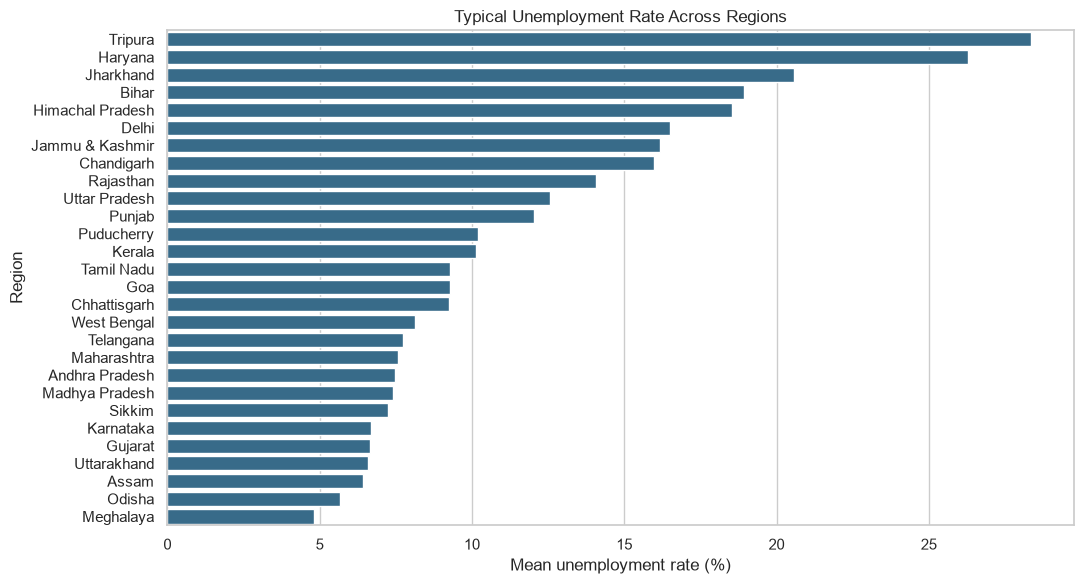

In [ ]:
regional_mean = data.groupby('region', as_index=False)['unemployment_rate'].mean().sort_values('unemployment_rate', ascending=False)
display(regional_mean.round(2))
sns.barplot(data=regional_mean, y='region', x='unemployment_rate', color='#2A6F97')
plt.title('Typical Unemployment Rate Across Regions')
plt.xlabel('Mean unemployment rate (%)')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

**What this shows:** The bars compare the long-run average in each region represented by the file. A high position means unemployment was more elevated on average during the observed months, but the chart does not explain why.

## Monthly movement

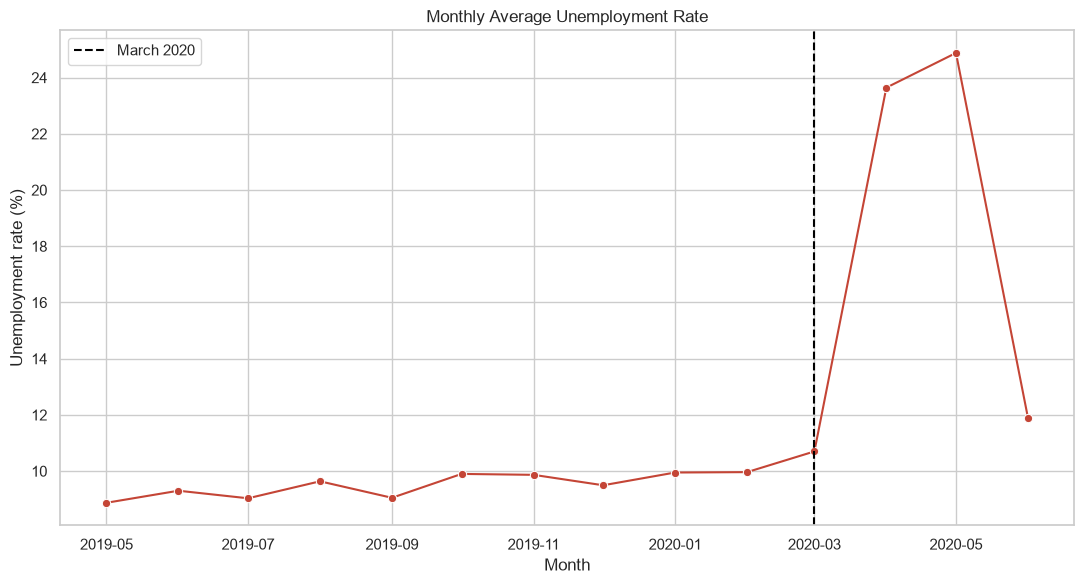

In [ ]:
monthly_mean = data.groupby('month', as_index=False)['unemployment_rate'].mean()
sns.lineplot(data=monthly_mean, x='month', y='unemployment_rate', marker='o', color='#C44536')
plt.axvline(pd.Timestamp('2020-03-01'), color='black', linestyle='--', label='March 2020')
plt.title('Monthly Average Unemployment Rate')
plt.xlabel('Month')
plt.ylabel('Unemployment rate (%)')
plt.legend()
plt.tight_layout()
plt.show()

**What this shows:** The monthly curve gives the national-level time context. The vertical marker makes it easier to compare the pandemic-era jump with the earlier baseline, while the separate regional plot checks whether that movement was shared.

## Time series for three major regions

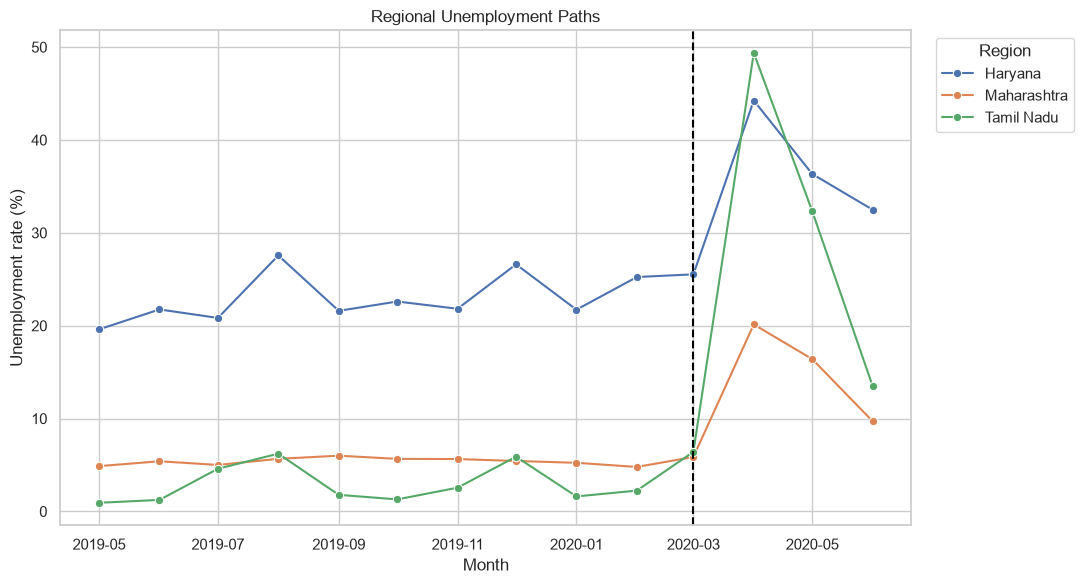

In [ ]:
priority = ['Maharashtra', 'Tamil Nadu', 'Haryana']
chosen = [name for name in priority if name in set(data['region'])]
if len(chosen) < 3:
    chosen = data['region'].value_counts().head(3).index.tolist()
region_series = data[data['region'].isin(chosen)].groupby(['month','region'], as_index=False)['unemployment_rate'].mean()
sns.lineplot(data=region_series, x='month', y='unemployment_rate', hue='region', marker='o')
plt.axvline(pd.Timestamp('2020-03-01'), color='black', linestyle='--')
plt.title('Regional Unemployment Paths')
plt.xlabel('Month')
plt.ylabel('Unemployment rate (%)')
plt.legend(title='Region', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

**What this shows:** The lines expose differences hidden by an all-region average. Regions with taller peaks experienced a stronger short-term shock, while the length of the recovery indicates how persistent the change was in this sample.

## Ten highest regional averages

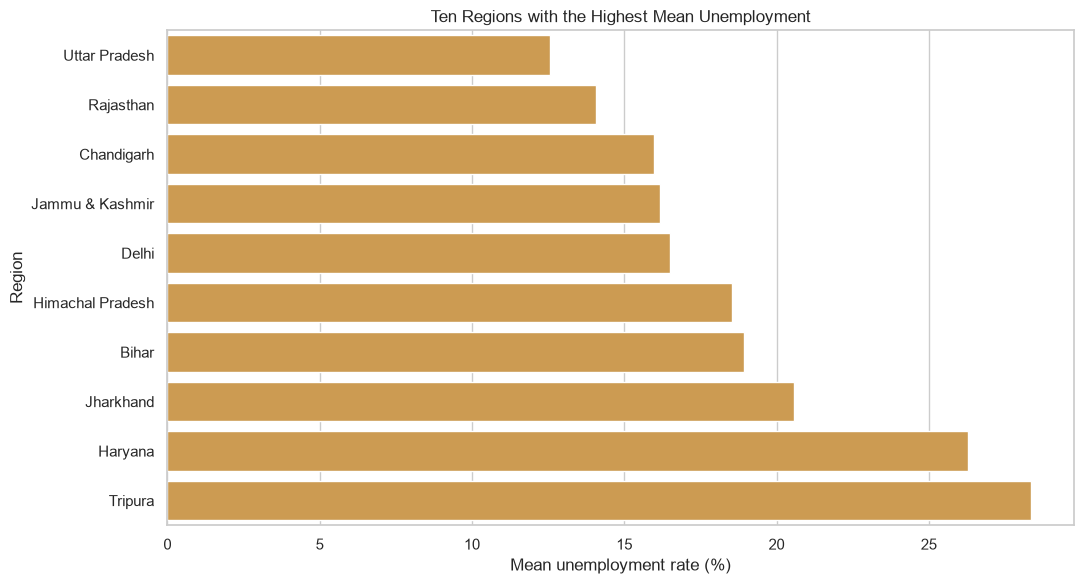

In [ ]:
top_ten = regional_mean.head(10).sort_values('unemployment_rate')
sns.barplot(data=top_ten, y='region', x='unemployment_rate', color='#E09F3E')
plt.title('Ten Regions with the Highest Mean Unemployment')
plt.xlabel('Mean unemployment rate (%)')
plt.ylabel('Region')
plt.tight_layout()
plt.show()

**What this shows:** This is a compact view of the highest average rates. It is a ranking for this dataset and date range, rather than a permanent classification of regional labour markets.

## Relationships among labour-market measures

,unemployment_rate,employed,labour_participation_rate
unemployment_rate,1.000,-0.223,0.003
employed,-0.223,1.000,0.011
labour_participation_rate,0.003,0.011,1.000


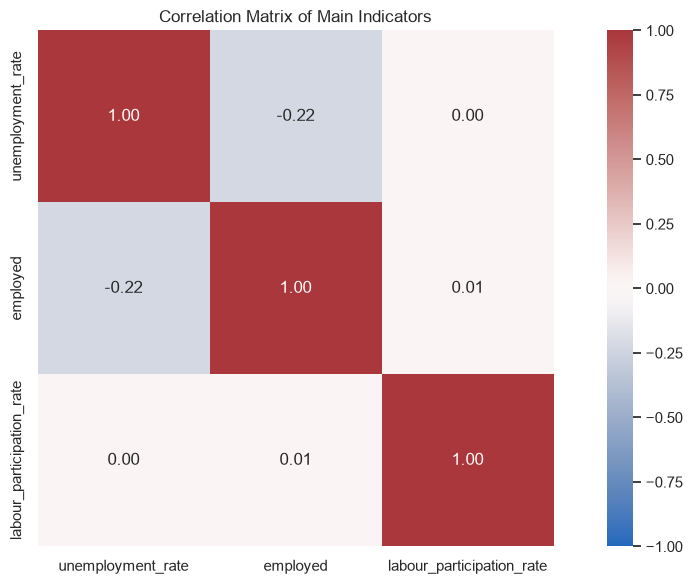

In [ ]:
correlation = data[['unemployment_rate','employed','labour_participation_rate']].corr()
display(correlation.round(3))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1, square=True)
plt.title('Correlation Matrix of Main Indicators')
plt.tight_layout()
plt.show()

**What this shows:** The heatmap identifies indicators that tend to move together. These are associations only: time trends, region mix, and other unmeasured factors can affect the coefficients.

## Before and after the COVID-19 split

,unemployment_rate,employed,labour_participation_rate
period,,,
Pre-COVID,9.51,7466027.87,43.89
Post-COVID,17.77,6517203.34,39.33


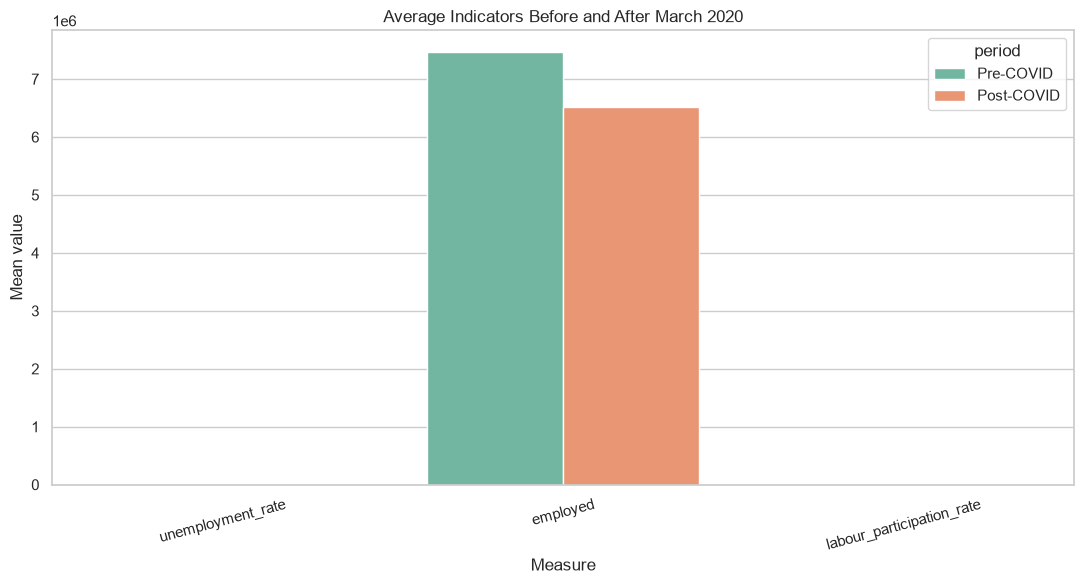

In [ ]:
split_date = pd.Timestamp('2020-03-01')
data['period'] = np.where(data['date'] < split_date, 'Pre-COVID', 'Post-COVID')
period_means = data.groupby('period')[['unemployment_rate','employed','labour_participation_rate']].mean().reindex(['Pre-COVID','Post-COVID'])
display(period_means.round(2))
long_period = period_means.reset_index().melt(id_vars='period', var_name='indicator', value_name='mean')
sns.barplot(data=long_period, x='indicator', y='mean', hue='period', palette='Set2')
plt.title('Average Indicators Before and After March 2020')
plt.xlabel('Measure')
plt.ylabel('Mean value')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**What this shows:** The two group means quantify the direction of change after March 2020. A rise in unemployment alongside a fall in employment or participation would support the interpretation of a pandemic-era labour-market disruption, but this simple split cannot prove causality.

## Conclusion

The analysis combines regional averages, monthly movement, three-region trajectories, a top-ten ranking, indicator correlations, and a pre/post comparison. The strongest conclusions are descriptive: where unemployment was higher, when the major movement occurred, and how the measured indicators changed around March 2020. The Kaggle dataset should be cited as the source in any submitted report.